<a href="https://colab.research.google.com/github/Seven8ight/AI_CAT_2/blob/main/CAT_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Qn 1
As per your assigned groups for the semester, identify the ML approach and
algorithms that are relevant to the dataset & expected output of your application.
Include this information in the shared spreadsheet of the semester groups.

### Answer
- AI Application: Classification
- Algorithm/Approach: Logistic Regression

**Why**: Its simple in that the model simply takes up a weighted sum of the variables e.g. peer pressure, academic pressure etc. And is also fast because the resultant output is the weighted sum of the variables in one quick compute which can run on mobile applications very quickly. Furthermore, since each variable has its own weight, we can analyze and identify which specific factor pushed a student towards High stress levels, which allows the model properly predict to them a relief measure.


Q2:
---



In your notebook/development environment, critically detail the data cleaning
process taken from exploration to the final dataset for modelling. As part of the
EDA, derive at least 4 observations from the dataset.



Exploration:
---



The project uses a public Kaggle Dataset chosen because it explicitly has a stress-level target and self-reported data which is consistent with the project's idea to avoid wearables.


The Cleaning Process:
---





In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

from google.colab import files

uploaded = files.upload()
df = pd.read_csv("academic_stress_raw.csv")
df.shape

Saving academic_stress_raw.csv to academic_stress_raw.csv


(140, 9)

First , we read the Excel sheet using the imported pandas library and analyse rows and columns using df.shape.

In [ ]:
df.head()

,Timestamp,Academic_Stage,Peer_Pressure,Academic_Pressure_Home,Study_Environment,Coping_Strategy,Bad_Habits,Academic_Competition,Stress_Index
0,24/07/2025 22:05:39,undergraduate,4,5,Noisy,Analyze the situation and handle it with intel...,No,3,5
1,24/07/2025 22:05:52,undergraduate,3,4,Peaceful,Analyze the situation and handle it with intel...,No,3,3
2,24/07/2025 22:06:39,undergraduate,1,1,Peaceful,"Social support (friends, family)",No,2,4
3,24/07/2025 22:06:45,undergraduate,3,2,Peaceful,Analyze the situation and handle it with intel...,No,4,3
4,24/07/2025 22:08:06,undergraduate,3,3,Peaceful,Analyze the situation and handle it with intel...,No,4,5


Return first 5 rows with head()

In [ ]:
df.isna().sum()

,0
Timestamp,0
Academic_Stage,0
Peer_Pressure,0
Academic_Pressure_Home,0
Study_Environment,0
Coping_Strategy,0
Bad_Habits,0
Academic_Competition,0
Stress_Index,0


All columns are zero (lack null values) except one instance on Study Environment. We drop the single row instead of imputing it with the mode which would be inserting a response the student never gave.  

In [ ]:
df = df.dropna(subset=["Study Environment"]).reset_index(drop=True)
df.shape

(139, 9)

Dropped the null row and on checking shape , it has reduced from 140 to 139.

In [ ]:
print("Fully identical rows:", df.duplicated().sum())
print("Identical excluding Timestamp:", df.drop(columns=["Timestamp"]).duplicated().sum())

Fully identical rows: 0
Identical excluding Timestamp: 8


Check for identical rows. Also check for identical rows excluding timestamp.

In [ ]:
dup_mask = df.drop(columns=["Timestamp"]).duplicated(keep=False)
df[dup_mask].sort_values(list(df.columns[1:-1]))

,Timestamp,Academic_Stage,Peer_Pressure,Academic_Pressure_Home,Study_Environment,Coping_Strategy,Bad_Habits,Academic_Competition,Stress_Index
3,24/07/2025 22:06:45,undergraduate,3,2,Peaceful,Analyze the situation and handle it with intel...,No,4,3
45,24/07/2025 22:34:41,undergraduate,3,2,Peaceful,Analyze the situation and handle it with intel...,No,4,3
21,24/07/2025 22:18:44,undergraduate,3,3,Peaceful,Analyze the situation and handle it with intel...,No,4,3
22,24/07/2025 22:18:55,undergraduate,3,3,Peaceful,Analyze the situation and handle it with intel...,No,4,3
20,24/07/2025 22:18:02,undergraduate,4,3,Peaceful,Analyze the situation and handle it with intel...,No,4,4
25,24/07/2025 22:19:22,undergraduate,4,3,Peaceful,Analyze the situation and handle it with intel...,No,4,4


Inspect returned rows. Check on timestamp.
Decision made to keep them based on discrepancy of timestamps hence wouldn't have been responses made in one sitting.

In [ ]:
df = df.rename(columns={
    "Your Academic Stage": "Academic_Stage",
    "Peer pressure": "Peer_Pressure",
    "Academic pressure from your home": "Academic_Pressure_Home",
    "Study Environment": "Study_Environment",
    "What coping strategy you use as a student?": "Coping_Strategy",
    "Do you have any bad habits like smoking, drinking on a daily basis?": "Bad_Habits",
    "What would you rate the academic  competition in your student life": "Academic_Competition",
    "Rate your academic stress index ": "Stress_Index",
})
df.columns.tolist()


['Timestamp',
 'Academic_Stage',
 'Peer_Pressure',
 'Academic_Pressure_Home',
 'Study_Environment',
 'Coping_Strategy',
 'Bad_Habits',
 'Academic_Competition',
 'Stress_Index']

Rename columns for consistency and ease.

In [ ]:
for c in ["Academic_Stage", "Study_Environment", "Coping_Strategy", "Bad_Habits"]:
    print(c, "->", sorted(df[c].unique()))

Academic_Stage -> ['high school', 'post-graduate', 'undergraduate']
Study_Environment -> ['Noisy', 'Peaceful', 'disrupted']
Coping_Strategy -> ['Analyze the situation and handle it with intellect', 'Emotional breakdown (crying a lot)', 'Social support (friends, family)']
Bad_Habits -> ['No', 'Yes', 'prefer not to say']


Check categorical columns for consistency.

In [ ]:
df["Study_Environment"] = df["Study_Environment"].str.strip().str.capitalize()


Fix the discrepancy between 'disrupted' and 'Disrupted'.

In [ ]:
df["Bad_Habits"].value_counts()


,count
Bad_Habits,
No,122
Yes,10
prefer not to say,7


Keep prefer not to say as an option.

In [ ]:
df["Coping_Strategy"].value_counts()

,count
Coping_Strategy,
Analyze the situation and handle it with intellect,87
Emotional breakdown (crying a lot),31
"Social support (friends, family)",21


Checked , three consistent categories , no cleaning needed

In [ ]:
df["Academic_Stage"].value_counts()

,count
Academic_Stage,
undergraduate,99
high school,29
post-graduate,11


In [ ]:
df = df[df["Academic_Stage"] != "high school"].reset_index(drop=True)
df.shape

(110, 9)

The project is concerned with university students. Drop the high school academic stage which is a population the app isn't targeted for.

In [ ]:
df = df[df["Academic_Stage"] != "post-graduate"].reset_index(drop=True)
df.shape

(99, 9)

On dropping the high school academic stage , an almost 90/10 split is left between undergraduate and post-graduate students. The decision is made to drop post-graduate students as they have an unsubstantial proportion in the dataset.
As a result , we avoid noisy and difficult to trust data from the post-graduate students.


In [ ]:
df = df[df["Academic_Stage"] == "undergraduate"].reset_index(drop=True)
df = df.drop(columns=["Academic_Stage"])
df.shape

(99, 8)

Drop the entire column since it has zero variance. It therefore cannot split or separate anything.


Exploratory Data Analysis (EDA) :
---



In [ ]:
df["Stress_Index"].value_counts().sort_index()

,count
Stress_Index,
1,4
2,8
3,26
4,38
5,23


Class 1 and 2 are too thin. Revert into a Low,Medium,High metric.

In [ ]:
def bin_stress(x):
    if x <= 2: return "Low"
    elif x == 3: return "Medium"
    else: return "High"

df["Stress_Level"] = df["Stress_Index"].apply(bin_stress)
df["Stress_Level"].value_counts()

,count
Stress_Level,
High,61
Medium,26
Low,12


The Low,Medium and High classification is still imbalanced towards high but each class has enough rows for a 5-fold split. Stress_Leve; is the actual modelling target.

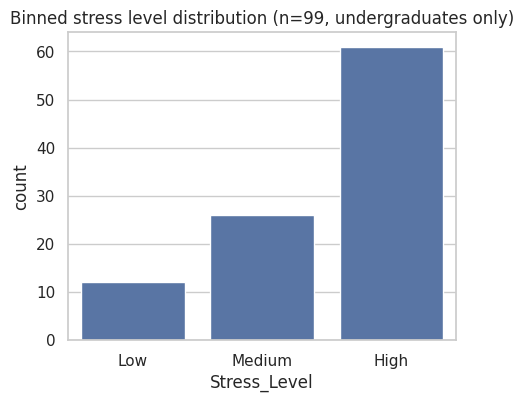

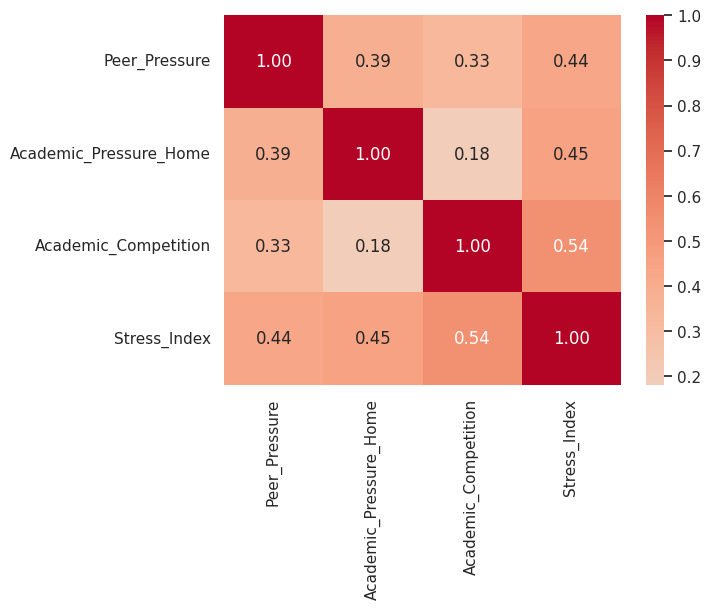

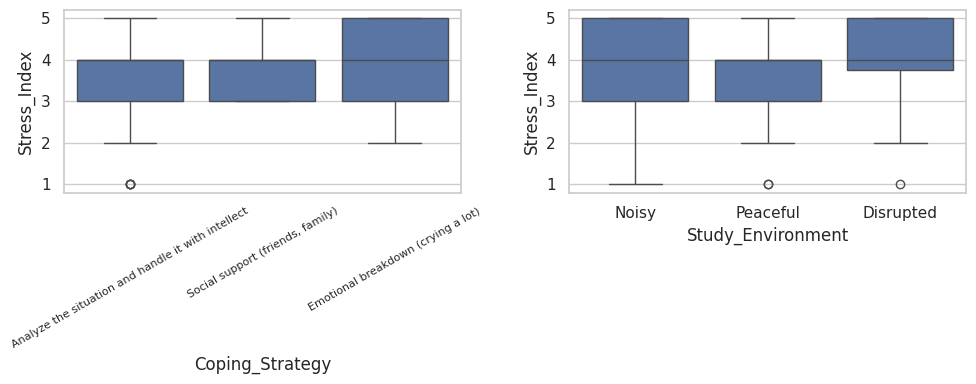

In [ ]:
fig, ax = plt.subplots(figsize=(5,4))
sns.countplot(data=df, x="Stress_Level", order=["Low","Medium","High"], ax=ax)
ax.set_title("Binned stress level distribution (n=99, undergraduates only)")
plt.show()
#Visualises the Low,Medium,High Stress_Level

num_cols = ["Peer_Pressure", "Academic_Pressure_Home", "Academic_Competition", "Stress_Index"]
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()
#Numeric features correlation with stress

fig, axes = plt.subplots(1, 2, figsize=(10,4))
sns.boxplot(data=df, x="Coping_Strategy", y="Stress_Index", ax=axes[0])
axes[0].tick_params(axis="x", rotation=30, labelsize=8)
sns.boxplot(data=df, x="Study_Environment", y="Stress_Index", ax=axes[1])
plt.tight_layout(); plt.show()
#effects of different coping strategies and study environments on stress

Exploratory Data Analysis (EDA) Plots.

In [ ]:
df.to_csv("academic_stress_clean.csv" , index=False)

# Qn 3

Describe the modelling approach taken on the identified base model. Ensure you
have applied appropriate measures as guided by other similar approaches to verify
the validity of the results

**Features used:** Peer_Pressure, Academic_Pressure_Home, Academic_Competition, Study_Environment, Coping_Strategy, Bad_Habits.

**Target:** Stress_level

**Validation Measure:** Used 5-fold stratified cross-validation since with only 50 rows, a single test split would be very noisy. Hence the data is split into 5 folds; 4 folds are used by the model while the 1 fold is left out

In [ ]:
import os
import pandas as pd
from pandas import DataFrame
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Define missing variables
RANDOM_STATE = 42

df:DataFrame
# Ensure the cleaned dataframe containing 'Stress_Level' is loaded
if os.path.exists("academic_stress_clean.csv"):
    df = pd.read_csv("academic_stress_clean.csv")
else:
    # Fallback/dynamic cleanup in case the clean CSV wasn't written to disk yet
    if "Stress_Index" in df.columns:
        def bin_stress(x):
            if x <= 2: return "Low"
            elif x == 3: return "Medium"
            else: return "High"
        df["Stress_Level"] = df["Stress_Index"].apply(bin_stress)

feature_cols_num = ["Peer_Pressure", "Academic_Pressure_Home", "Academic_Competition"]
feature_cols_cat = ["Study_Environment", "Coping_Strategy", "Bad_Habits"]
X = df[feature_cols_num + feature_cols_cat]
y = df["Stress_Level"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), feature_cols_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), feature_cols_cat),
])

logreg_pipeline = Pipeline([
    ("pre", preprocessor),
    ("logreg", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

In [ ]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_validate

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = cross_validate(logreg_pipeline, X, y, cv=skf, scoring=["accuracy", "f1_macro"])

for metric in ["accuracy", "f1_macro"]:
    scores = cv_results[f"test_{metric}"]
    print(f"{metric}: per-fold={np.round(scores, 3)}  mean={scores.mean():.3f}  std={scores.std():.3f}")

accuracy: per-fold=[0.5 0.8 0.6 0.5 0.4]  mean=0.560  std=0.136
f1_macro: per-fold=[0.238 0.786 0.613 0.222 0.19 ]  mean=0.410  std=0.243


Mean accuracy sits around 0.56 but swings from 0.4 to 0.8 fold-to-fold, and
macro-F1 (which treats all three classes equally) is noticeably lower. With only 10 samples per fold, that
instability is expected — it's clear that **N=50 is a prototyping sample, not a basis for
strong claims**, which lines up with the stated limitation
about small single-institution samples.

In [ ]:
# Secondary robustness check: does the regularisation strength (C) matter here?
print(f"{'C':<8}{'mean_acc':<12}{'std_acc'}")
for C in [0.01, 0.1, 1.0, 10.0]:
    pipe_c = Pipeline([("pre", preprocessor), ("logreg", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, C=C))])
    scores = cross_validate(pipe_c, X, y, cv=skf, scoring="accuracy")["test_score"]
    print(f"{C:<8}{scores.mean():<12.3f}{scores.std():.3f}")


C       mean_acc    std_acc
0.01    0.580       0.040
0.1     0.540       0.080
1.0     0.560       0.136
10.0    0.620       0.147


Accuracy barely moves across regularisation strengths and the differences
are well within the fold-to-fold noise seen above — at this sample size we
can't conclude that tuning `C` meaningfully helps.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
logreg_pipeline.fit(X_train, y_train)
y_pred = logreg_pipeline.predict(X_test)
print(f"Held-out test set: {len(y_test)} rows\n")
print(classification_report(y_test, y_pred, zero_division=0))

Held-out test set: 13 rows

              precision    recall  f1-score   support

        High       0.55      0.86      0.67         7
         Low       0.00      0.00      0.00         2
      Medium       0.50      0.25      0.33         4

    accuracy                           0.54        13
   macro avg       0.35      0.37      0.33        13
weighted avg       0.45      0.54      0.46        13



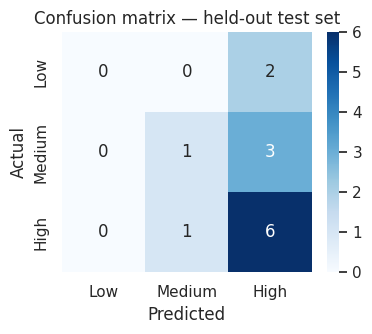

In [ ]:
from sklearn.metrics import confusion_matrix

labels_order = ["Low", "Medium", "High"]
cm = confusion_matrix(y_test, y_pred, labels=labels_order)
fig, ax = plt.subplots(figsize=(4, 3.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels_order, yticklabels=labels_order, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion matrix — held-out test set")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score

y_test_bin = label_binarize(y_test, classes=labels_order)
y_proba = logreg_pipeline.predict_proba(X_test)
proba_cols = list(logreg_pipeline.named_steps["logreg"].classes_)
col_idx = [proba_cols.index(l) for l in labels_order]
y_proba_ordered = y_proba[:, col_idx]
auc = roc_auc_score(y_test_bin, y_proba_ordered, average="macro", multi_class="ovr")
print(f"Macro one-vs-rest AUC-ROC (held-out test set): {auc:.3f}")

Macro one-vs-rest AUC-ROC (held-out test set): 0.619


On the held-out split, the model never correctly identifies a `Low`-stress
student (0/2 recall) — unsurprising with only 6 `Low` examples in the whole
dataset, most of which end up in the training fold by chance. The
macro-average AUC-ROC of ~0.62 says the model is doing somewhat better than
a coin flip at ranking stress levels, but it is not yet a reliable
classifier. That gap between "better than random" and "reliable" is
exactly what the real self-collected dataset is meant to close.


In [ ]:
ohe = logreg_pipeline.named_steps["pre"].named_transformers_["cat"]
cat_names = ohe.get_feature_names_out(feature_cols_cat)
all_feature_names = feature_cols_num + list(cat_names)
coef_df = pd.DataFrame(
    logreg_pipeline.named_steps["logreg"].coef_,
    index=logreg_pipeline.named_steps["logreg"].classes_,
    columns=all_feature_names,
).T
coef_df.round(3)


,High,Low,Medium
Peer_Pressure,0.389,-0.861,0.472
Academic_Pressure_Home,0.376,-0.394,0.017
Academic_Competition,0.175,-0.304,0.129
Study_Environment_Noisy,0.286,-0.020,-0.266
Study_Environment_Peaceful,-0.424,-0.323,0.747
Study_Environment_disrupted,0.137,0.342,-0.478
Coping_Strategy_Analyze the situation and handle it with intellect,-0.466,0.826,-0.360
Coping_Strategy_Emotional breakdown (crying a lot),0.050,-0.218,0.168
"Coping_Strategy_Social support (friends, family)",0.415,-0.609,0.193
Bad_Habits_No,0.017,0.064,-0.081


Reading these as one-vs-rest coefficients: higher `Peer_Pressure` and
`Academic_Competition` push toward the `High` class and away from `Low`,
which matches the correlation direction seen in the EDA section — a useful
sanity check that the model learned something consistent with the data,
even if its overall accuracy is still modest.



4 Observations:
---
1. Scope driven filtering reduced rows of the dataset from 139 to 99 - That is, dropping of high school and post-graduate students who were out of the scope for the potential model users.
2. Academic_Stage was a keepable column but on filtering , it retained only undergraduate students - a column with zero variance is unimpactful in model training.
3. The target is still imbalanced even after binning (High: 61 vs Low: 12) — which may be a modelling risk moving forward.
4. Academic_Competition is the strongest single predictor (r≈0.54) with the highest correlation to stress.



## Qn 4

Determine other methods that can be used to further validate the results of the base
model. A recommended approach would be to develop models that follow the same
process and compare performances of each. See figure 6 of this research paper to get
an idea of how this can be accomplished.

Answer: Currently we are using logistic regression because its fast and easy, however relying on a single model makes it difficult to tell if our accuracy is good or if a different machine learning approach would perform better on the same dataset. To further validate the results of the base model,we aim to take the following steps:
1. Compare multiple models families - Using the exact same cleaned features, we will train at least 2 additional types of classifiers alongside Logistic Regression:
  - Decision Trees - Suitable for capturing simple conditional rules and non-linear patterns e.g. high home pressure with noisy study environment.
  - K-Nearest Neighbours (K-NN): A simple model based on intuition that classifies a student based on how similar their survey responses are to former examples.
2. Use a fair evaluation protocol where every model from step 1 is evaluated using the same 5-fold cross-validation setup and standard performance checks. An analysis of the comparison alows us to directly compare the strenghts and weaknesses of each model compared.
3. Tune key settings once more data is collected - with the current small sample size of 50 rows, heavy tuning risks overfitting. Once full check-in data is gathered, we will run a grid search to automatically find the best settings for each model.
4. Test a model that respects natural ranking of stress - Standard machine learning algorithms treat stress levels i.e. low, medium and high as completely separate, unrelated categories whereas in reality, stress follows a natural step-by-step progression. We will test a model specifically designed for ranked data so the system understands that mistaking a high stress student for a low stress one is a much bigger error than mistaking them for medium.